# S&P 500 Index — Exploratory Data Analysis

**Dataset:** `sp500.csv`  
**Nguồn:** Yahoo Finance, ticker ^GSPC  
**Vai trò trong dự án:** Nguồn external market cho bài toán Gold phiên kế tiếp.

## Mục tiêu phân tích

1. Hiểu cấu trúc, chất lượng, phân phối và phạm vi thời gian của nguồn dữ liệu.
2. Từ câu hỏi đặc thù của dataset, xây dựng các feature ứng viên và mô tả chúng.
3. Ghi nhận bằng chứng cần có trước khi quyết định giữ feature cho bài toán Gold phiên kế tiếp.

## Cấu trúc notebook

- **Part 1 — Data Profiling:** chỉ phân tích biến gốc.
- **Part 2 — Feature-oriented EDA:** câu hỏi → đại lượng cần đo → feature → EDA.


**Phạm vi:** snapshot EDA 2010–2026 của bốn nguồn Yahoo Finance; dữ liệu modeling 2005–2026 được xử lý riêng.

## Part 1 — Data Profiling

Phần này trả lời: dữ liệu có gì, có sạch không, phân phối cơ bản ra sao và trải dài trong thời gian nào? Chưa tạo return, MA, RSI hoặc MACD.


### 1.1 Thư viện và nguồn dữ liệu

In [1]:
from pathlib import Path



In [2]:

import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/modeling/horizons').is_dir() and (p/'notebook').is_dir())
DATA_DIR = ROOT / 'data/eda_2010_2026'
FILE_NAME = 'sp500.csv'
DATA_PATH = DATA_DIR / FILE_NAME
RAW_NUMERIC = ['Open', 'High', 'Low', 'Close', 'Volume']
TITLE = 'S&P 500 Index'


pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 100,
                     'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.25})

### 1.2 Đọc dữ liệu và chuẩn hóa định dạng

Chuẩn hóa tên Date, parse ngày và numeric trên bản sao. Đếm lỗi chuyển đổi; không impute và không xóa quan sát. Hai dòng metadata Yahoo không phải quan sát thị trường.


In [3]:

metadata = pd.read_csv(DATA_PATH, nrows=2)
print('\nThông tin metadata của file nguồn')
display(metadata)

if metadata.iloc[0, 0] == 'Ticker' and metadata.iloc[1, 0] == 'Date':
    print('Metadata đúng định dạng Ticker/Date.')
else:
    print('Cảnh báo: Metadata không đúng định dạng Ticker/Date dự kiến; cần kiểm tra cách đọc file.')

if (metadata.iloc[0, 1:] == '^GSPC').all():
    print('Ticker đúng nguồn dự kiến.')
else:
    print('Cảnh báo: Ticker không đúng nguồn dự kiến.')

raw = pd.read_csv(DATA_PATH, skiprows=[1, 2])

if set(raw.columns) == {'Price', 'Open', 'High', 'Low', 'Close', 'Volume'}:
    print('Các cột đúng schema dự kiến.')
else:
    print('Cảnh báo: Các cột trong file khác schema dự kiến; xem tên cột trước khi phân tích tiếp.')

df = raw.rename(columns={'Price': 'Date'}).copy()


original_dates = df['Date'].copy()
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d', errors='coerce')
parse_failures = {'Date': int((original_dates.notna() & df['Date'].isna()).sum())}

for column in RAW_NUMERIC:
    original_values = df[column].copy()
    df[column] = pd.to_numeric(original_values, errors='coerce')
    parse_failures[column] = int((original_values.notna() & df[column].isna()).sum())

input_sorted = df['Date'].is_monotonic_increasing
df = df.sort_values('Date', kind='stable').reset_index(drop=True)
print('\n5 dòng đầu của dữ liệu')
display(df.head())
print('\n5 dòng cuối của dữ liệu')
display(df.tail())


Thông tin metadata của file nguồn


,Price,Close,High,Low,Open,Volume
0,Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
1,Date,NaN,NaN,NaN,NaN,NaN


Metadata đúng định dạng Ticker/Date.
Ticker đúng nguồn dự kiến.
Các cột đúng schema dự kiến.

5 dòng đầu của dữ liệu


,Date,Close,High,Low,Open,Volume
0,2010-01-04,1132.989990,1133.869995,1116.560059,1116.560059,3991400000
1,2010-01-05,1136.520020,1136.630005,1129.660034,1132.660034,2491020000
2,2010-01-06,1137.140015,1139.189941,1133.949951,1135.709961,4972660000
3,2010-01-07,1141.689941,1142.459961,1131.319946,1136.270020,5270680000
4,2010-01-08,1144.979980,1145.390015,1136.219971,1140.520020,4389590000



5 dòng cuối của dữ liệu


,Date,Close,High,Low,Open,Volume
4198,2026-09-14,7619.979980,7647.990234,7592.279785,7611.439941,4963750000
4199,2026-09-15,7585.729980,7617.259766,7572.689941,7612.299805,5154930000
4200,2026-09-16,7551.810059,7626.790039,7507.770020,7601.250000,5307920000
4201,2026-09-17,7637.759766,7646.859863,7611.810059,7631.439941,5058210000
4202,2026-09-18,7650.500000,7657.169922,7610.520020,7657.169922,8858350000


### 1.3 Kích thước và phạm vi thời gian

“Số ngày quan sát” là số Date hợp lệ khác nhau; khác với số ngày lịch giữa đầu và cuối chuỗi.


In [4]:

overview = pd.DataFrame([{
    'Rows': len(df), 'Columns_including_Date': len(df.columns),
    'Start_date': df['Date'].min(), 'End_date': df['Date'].max(),
    'Unique_observed_dates': df['Date'].nunique(),
    'Calendar_span_days': (df['Date'].max() - df['Date'].min()).days + 1,
    'Rows_removed': len(raw) - len(df), 'Originally_sorted': input_sorted
}])
print('\nTổng quan kích thước và phạm vi thời gian')
display(overview)
print('\nSố dòng quan sát theo năm')
display(df.groupby(df['Date'].dt.year).size().rename('Observed_rows').to_frame())


Tổng quan kích thước và phạm vi thời gian


,Rows,Columns_including_Date,Start_date,End_date,Unique_observed_dates,Calendar_span_days,Rows_removed,Originally_sorted
0,4203,6,2010-01-04,2026-09-18,4203,6102,0,True



Số dòng quan sát theo năm


,Observed_rows
Date,
2010,252
2011,252
2012,250
2013,252
2014,252
2015,252
2016,252
2017,251
2018,251


### 1.4 Data schema và ý nghĩa biến

Phân biệt đơn vị giá/chỉ số với khối lượng. Những mô tả nguồn chưa xác minh được ghi rõ.


In [5]:

column_meaning = {'Date': 'Nhãn ngày quan sát của nguồn, chưa xác minh giờ chốt', 'Open': 'Giá/mức chỉ số mở cửa do nguồn cung cấp', 'High': 'Giá/mức chỉ số cao nhất theo nguồn', 'Low': 'Giá/mức chỉ số thấp nhất theo nguồn', 'Close': 'Giá/mức chỉ số Close; cần xác minh close/settlement với futures', 'Volume': 'Khối lượng do nguồn cung cấp; không so sánh trực tiếp giữa các thị trường'}

column_units = {'Open': 'Index points', 'High': 'Index points', 'Low': 'Index points', 'Close': 'Index points', 'Volume': 'Source-reported volume; cần xác minh đơn vị', 'Date': 'YYYY-MM-DD'}

schema = pd.DataFrame({
    'Column': df.columns,
    'Dtype': [str(df[c].dtype) for c in df.columns],
    'Meaning': [column_meaning[c] for c in df.columns],
    'Unit': [column_units[c] for c in df.columns]
})
print('\nCấu trúc dữ liệu và ý nghĩa từng cột')
display(schema)


Cấu trúc dữ liệu và ý nghĩa từng cột


,Column,Dtype,Meaning,Unit
0,Date,datetime64[us],"Nhãn ngày quan sát của nguồn, chưa xác minh gi...",YYYY-MM-DD
1,Close,float64,Giá/mức chỉ số Close; cần xác minh close/settl...,Index points
2,High,float64,Giá/mức chỉ số cao nhất theo nguồn,Index points
3,Low,float64,Giá/mức chỉ số thấp nhất theo nguồn,Index points
4,Open,float64,Giá/mức chỉ số mở cửa do nguồn cung cấp,Index points
5,Volume,int64,Khối lượng do nguồn cung cấp; không so sánh tr...,Source-reported volume; cần xác minh đơn vị


### 1.5 Missing values, duplicates và độ phủ ngày

**Câu hỏi:** có thiếu giá trị trong các dòng đã có, có ngày trùng, hoặc có ngày cần đối chiếu lịch nguồn không?

Phân biệt **missing cell** với **ngày không có bản ghi**. Daily data không nhất thiết có bản ghi cho mọi ngày lịch. Cuối tuần được tách riêng; ngày thứ Hai–thứ Sáu vắng mặt vẫn có thể là ngày nghỉ hoặc khác biệt lịch phiên, chưa gọi là lỗi crawl.

**Thống kê và biểu đồ:** số lượng ngắn gọn, biểu đồ ngày vắng theo năm và vị trí các ngày thường vắng. Bảng chi tiết chỉ hiện tối đa 20 dòng để xem mẫu. Không fill thêm ngày hoặc giá.



Thống kê dữ liệu thiếu và lỗi chuyển đổi kiểu dữ liệu


,Missing_cells,Missing_percent,Parse_failures
Close,0,0.0,0
Date,0,0.0,0
High,0,0.0,0
Low,0,0.0,0
Open,0,0.0,0
Volume,0,0.0,0


Duplicate raw rows: 0
Duplicate normalized rows: 0
Không có ngày bị trùng.

Các dòng có ngày bị trùng


,Date,Close,High,Low,Open,Volume



Tổng số ngày lịch không có bản ghi: 1,899
Trong đó, ngày cuối tuần: 1,742
Ngày thứ Hai–thứ Sáu cần đối chiếu lịch nguồn: 157
Các số này chưa phải số phiên bị mất dữ liệu.

Biểu đồ số ngày lịch vắng theo năm; năm đầu/cuối có thể chưa đủ năm


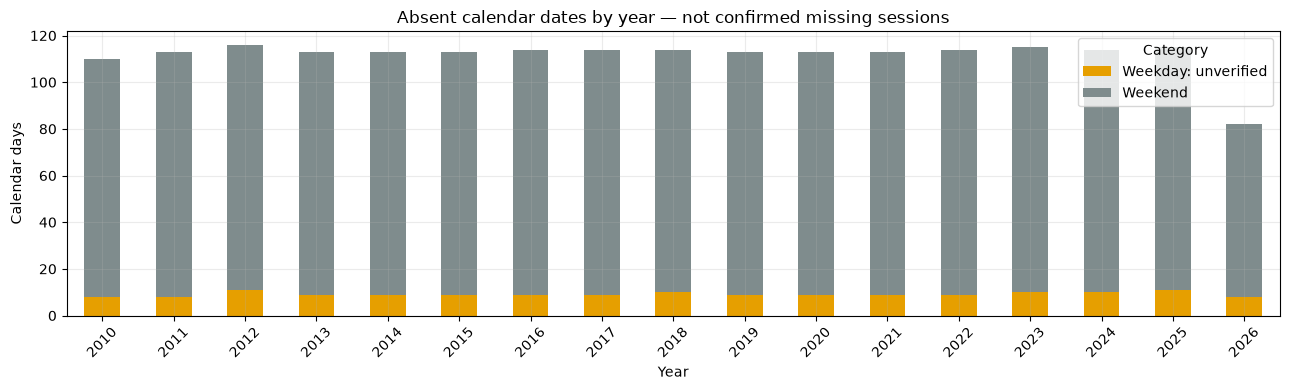


Vị trí các ngày thường vắng: dùng để rà soát xem có tập trung thành cụm không


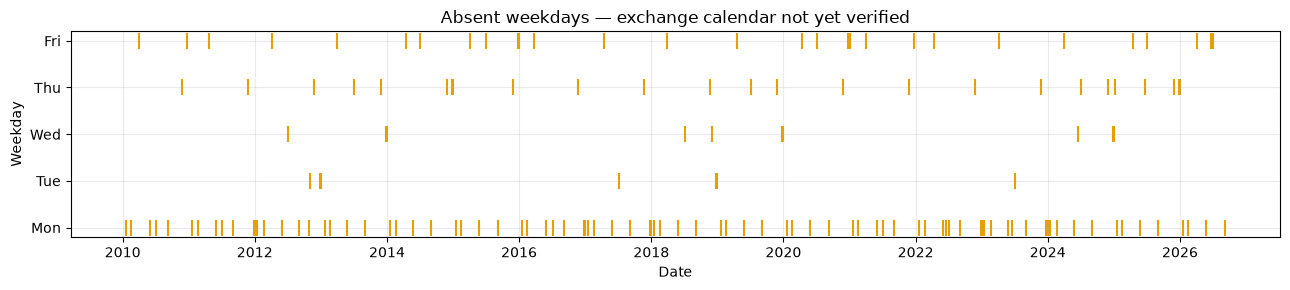


Tối đa 20 ngày thường vắng để đối chiếu (danh sách đầy đủ nằm trong weekday_gaps)


,Absent_date
4,2010-01-18
13,2010-02-15
26,2010-04-02
45,2010-05-31
56,2010-07-05
75,2010-09-06
98,2010-11-25
107,2010-12-24
116,2011-01-17
127,2011-02-21



10 khoảng cách ngày lớn nhất; vẫn có thể bao gồm cuối tuần/ngày nghỉ


,Date,Previous_date,Gap_calendar_days,Absent_dates_between
712,2012-10-31,2012-10-26,5.0,4.0
10,2010-01-19,2010-01-15,4.0,3.0
29,2010-02-16,2010-02-12,4.0,3.0
62,2010-04-05,2010-04-01,4.0,3.0
102,2010-06-01,2010-05-28,4.0,3.0
126,2010-07-06,2010-07-02,4.0,3.0
170,2010-09-07,2010-09-03,4.0,3.0
247,2010-12-27,2010-12-23,4.0,3.0
262,2011-01-18,2011-01-14,4.0,3.0
286,2011-02-22,2011-02-18,4.0,3.0


In [6]:


quality = pd.DataFrame({
    'Missing_cells': df.isna().sum(),
    'Missing_percent': df.isna().mean() * 100,
    'Parse_failures': pd.Series(parse_failures)
})
print('\nThống kê dữ liệu thiếu và lỗi chuyển đổi kiểu dữ liệu')
display(quality)
print('Duplicate raw rows:', int(raw.duplicated().sum()))
print('Duplicate normalized rows:', int(df.duplicated().sum()))

duplicate_dates = df.loc[df['Date'].notna(), 'Date'].duplicated().sum()
if duplicate_dates > 0:
    print(f'Cảnh báo: Có {duplicate_dates} ngày bị trùng.')
else:
    print('Không có ngày bị trùng.')
print('\nCác dòng có ngày bị trùng')
display(df.loc[df['Date'].notna() & df['Date'].duplicated(keep=False)])


observed_dates = pd.DatetimeIndex(df['Date'].dropna().unique()).sort_values()
if len(observed_dates) == 0:
    print('Không có ngày hợp lệ để kiểm tra độ phủ.')
else:
    calendar = pd.date_range(observed_dates.min(), observed_dates.max(), freq='D')
    absent_dates = calendar.difference(observed_dates)
    gap_table = pd.DataFrame({'Absent_date': absent_dates})
    gap_table['Weekend'] = gap_table['Absent_date'].dt.dayofweek >= 5
    weekday_gaps = gap_table.loc[~gap_table['Weekend']].copy()
    print(f'\nTổng số ngày lịch không có bản ghi: {len(gap_table):,}')
    print(f'Trong đó, ngày cuối tuần: {int(gap_table["Weekend"].sum()):,}')
    print(f'Ngày thứ Hai–thứ Sáu cần đối chiếu lịch nguồn: {len(weekday_gaps):,}')
    print('Các số này chưa phải số phiên bị mất dữ liệu.')

    
    gap_table['Year'] = gap_table['Absent_date'].dt.year
    gap_table['Category'] = gap_table['Weekend'].map({True: 'Weekend', False: 'Weekday: unverified'})
    yearly_gaps = pd.crosstab(gap_table['Year'], gap_table['Category'])
    if not yearly_gaps.empty:
        print('\nBiểu đồ số ngày lịch vắng theo năm; năm đầu/cuối có thể chưa đủ năm')
        yearly_gaps.plot.bar(stacked=True, figsize=(13, 4), color=['#e69f00', '#7f8c8d'])
        plt.title('Absent calendar dates by year — not confirmed missing sessions')
        plt.xlabel('Year')
        plt.ylabel('Calendar days')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    if weekday_gaps.empty:
        print('Không có ngày thứ Hai–thứ Sáu vắng trong phạm vi dữ liệu.')
    else:
        print('\nVị trí các ngày thường vắng: dùng để rà soát xem có tập trung thành cụm không')
        fig, ax = plt.subplots(figsize=(13, 3))
        ax.scatter(weekday_gaps['Absent_date'], weekday_gaps['Absent_date'].dt.dayofweek,
                   color='#e69f00', marker='|', s=130)
        ax.set_yticks([0, 1, 2, 3, 4], ['Mon', 'Tue', 'Wed', 'Thu', 'Fri'])
        ax.set(title='Absent weekdays — exchange calendar not yet verified', xlabel='Date', ylabel='Weekday')
        plt.tight_layout()
        plt.show()
        print('\nTối đa 20 ngày thường vắng để đối chiếu (danh sách đầy đủ nằm trong weekday_gaps)')
        display(weekday_gaps[['Absent_date']].head(20))

    
    consecutive_gaps = pd.Series(observed_dates).to_frame('Date')
    consecutive_gaps['Previous_date'] = consecutive_gaps['Date'].shift(1)
    consecutive_gaps['Gap_calendar_days'] = consecutive_gaps['Date'].diff().dt.days
    consecutive_gaps['Absent_dates_between'] = consecutive_gaps['Gap_calendar_days'] - 1
    long_gaps = consecutive_gaps.loc[consecutive_gaps['Gap_calendar_days'] > 1]
    if not long_gaps.empty:
        print('\n10 khoảng cách ngày lớn nhất; vẫn có thể bao gồm cuối tuần/ngày nghỉ')
        display(long_gaps.nlargest(10, 'Gap_calendar_days'))

### 1.6 Giá trị bất thường và tính hợp lệ

**Mục tiêu:** phân biệt cờ kiểm tra domain với điểm ngoài phân phối chung. Cả hai đều chưa chứng minh bản ghi sai.

IQR = Q3 − Q1. Điểm ngoài [Q1 − 1.5×IQR, Q3 + 1.5×IQR] được tô cam trên chuỗi thời gian, kèm hai hàng rào nét đứt và số điểm bị flag. Một cụm cam kéo dài có thể phản ánh thay đổi mặt bằng; điểm cam riêng lẻ cần xem các ngày lân cận. IQR toàn kỳ không xét thứ tự thời gian, không dùng làm quy tắc tự xóa hoặc ngưỡng modeling.

**Thống kê và biểu đồ:** bảng cờ kiểm tra có tiêu đề và biểu đồ thời gian cho từng biến gốc. Nếu IQR=0 do dữ liệu lặp nhiều, đọc cảnh báo và không coi mọi điểm khác mức phổ biến là lỗi.

**Dữ liệu thị trường:** cần đối chiếu ý nghĩa OHLC/Close, Volume và nguồn trước khi sửa. Uy tín nguồn không thay thế kiểm tra chất lượng.



Số dòng được gắn cờ theo từng kiểm tra chất lượng


,Flagged_rows
Invalid_date,0
Nonfinite_or_missing_numeric,0
High_below_Low,0
Open_outside_range,0
Close_outside_range,0
Nonpositive_price_review,0
Negative_volume,0
Zero_volume_review,1



Chi tiết các dòng được gắn cờ cần xem xét


,Date,Close,High,Low,Open,Volume,Invalid_date,Nonfinite_or_missing_numeric,High_below_Low,Open_outside_range,Close_outside_range,Nonpositive_price_review,Negative_volume,Zero_volume_review
3370,2023-05-24,4115.240234,4132.959961,4103.97998,4132.959961,0,False,False,False,False,False,False,False,True



Open — điểm ngoài hàng rào IQR theo thời gian
2/4,203 điểm hữu hạn bị flag (0.05%).
Hàng rào dưới: -1,715.95; hàng rào trên: 7,783.93.
Ngày bị flag đầu/cuối: 2026-08-14 đến 2026-08-17.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


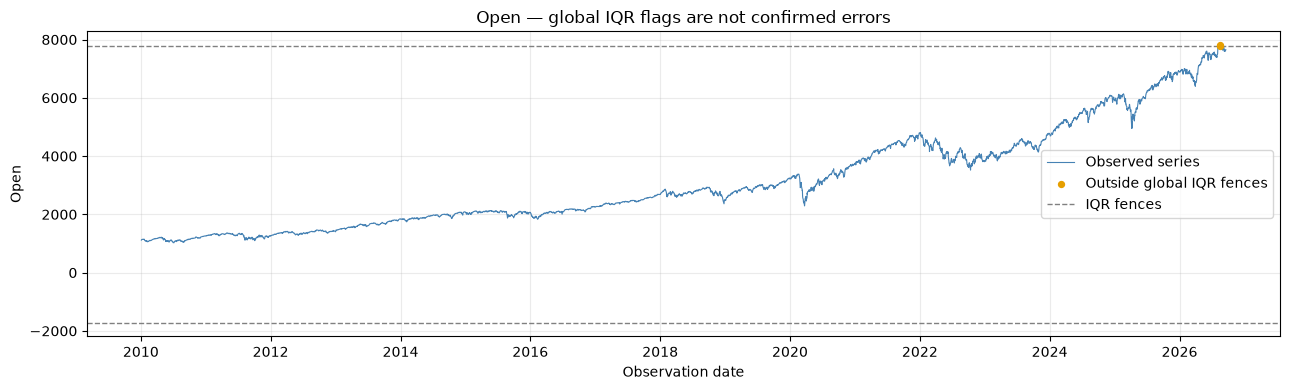


High — điểm ngoài hàng rào IQR theo thời gian
0/4,203 điểm hữu hạn bị flag (0.00%).
Hàng rào dưới: -1,728.37; hàng rào trên: 7,831.59.
Không có điểm ngoài hàng rào IQR; điều này không chứng minh dữ liệu hoàn toàn đúng.


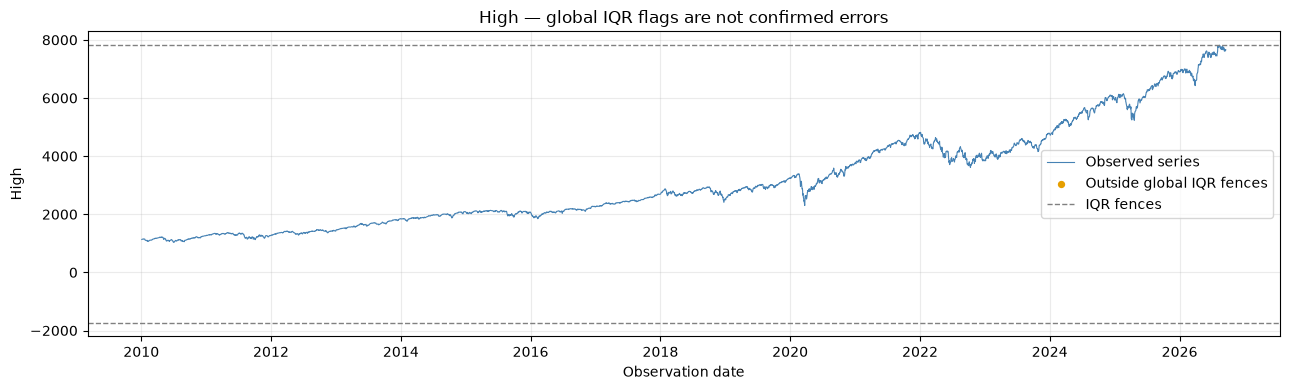


Low — điểm ngoài hàng rào IQR theo thời gian
5/4,203 điểm hữu hạn bị flag (0.12%).
Hàng rào dưới: -1,696.00; hàng rào trên: 7,732.51.
Ngày bị flag đầu/cuối: 2026-08-10 đến 2026-08-17.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


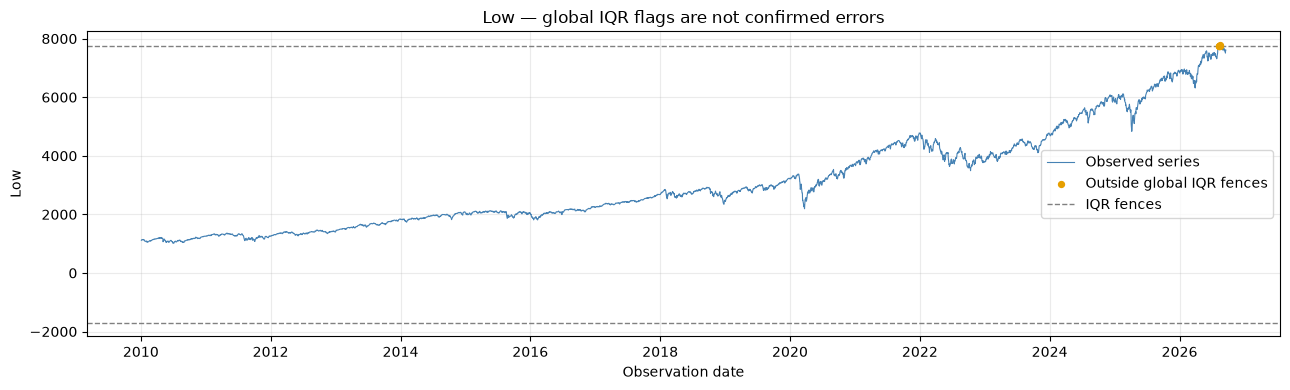


Close — điểm ngoài hàng rào IQR theo thời gian
2/4,203 điểm hữu hạn bị flag (0.05%).
Hàng rào dưới: -1,707.48; hàng rào trên: 7,773.76.
Ngày bị flag đầu/cuối: 2026-08-13 đến 2026-08-14.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


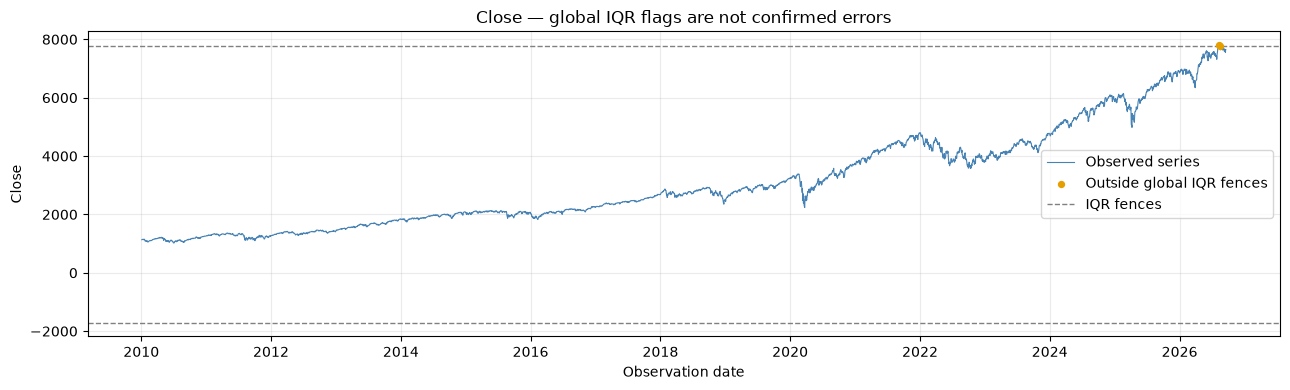


Volume — điểm ngoài hàng rào IQR theo thời gian
174/4,203 điểm hữu hạn bị flag (4.14%).
Hàng rào dưới: 1,727,555,000.00; hàng rào trên: 6,239,835,000.00.
Ngày bị flag đầu/cuối: 2010-01-21 đến 2026-09-18.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


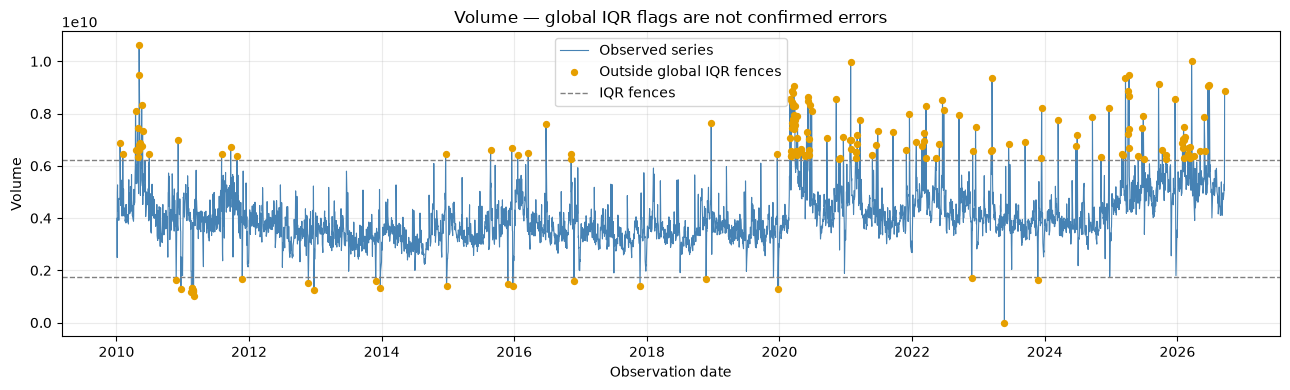

In [7]:

flags = pd.DataFrame(index=df.index)
flags['Invalid_date'] = df['Date'].isna()
flags['Nonfinite_or_missing_numeric'] = df[RAW_NUMERIC].isna().any(axis=1) | df[RAW_NUMERIC].isin([float('inf'), -float('inf')]).any(axis=1)
flags['High_below_Low'] = df['High'] < df['Low']
flags['Open_outside_range'] = (df['Open'] < df['Low']) | (df['Open'] > df['High'])
flags['Close_outside_range'] = (df['Close'] < df['Low']) | (df['Close'] > df['High'])
flags['Nonpositive_price_review'] = (df[['Open','High','Low','Close']] <= 0).any(axis=1)
flags['Negative_volume'] = df['Volume'] < 0
flags['Zero_volume_review'] = df['Volume'] == 0
print('\nSố dòng được gắn cờ theo từng kiểm tra chất lượng')
display(flags.sum().rename('Flagged_rows').to_frame())

flagged_rows = df.loc[flags.any(axis=1)].join(flags.loc[flags.any(axis=1)])
print('\nChi tiết các dòng được gắn cờ cần xem xét')
display(flagged_rows)


iqr_flags = pd.DataFrame(index=df.index)


for column in RAW_NUMERIC:
    values = df[column].replace([float('inf'), -float('inf')], float('nan'))
    valid_values = values.dropna()
    if valid_values.empty:
        print(f'\n{column}: không có giá trị hữu hạn để kiểm tra IQR.')
        continue

    
    q1 = valid_values.quantile(0.25)
    q3 = valid_values.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    
    outside_iqr = values.notna() & ((values < lower_fence) | (values > upper_fence))
    iqr_flags[column] = outside_iqr
    flagged_count = int(outside_iqr.sum())
    flagged_percent = 100 * flagged_count / len(valid_values)

    print(f'\n{column} — điểm ngoài hàng rào IQR theo thời gian')
    print(f'{flagged_count:,}/{len(valid_values):,} điểm hữu hạn bị flag ({flagged_percent:.2f}%).')
    print(f'Hàng rào dưới: {lower_fence:,.2f}; hàng rào trên: {upper_fence:,.2f}.')
    if iqr == 0:
        print('Lưu ý: IQR = 0, quy tắc này có thể flag nhiều điểm chỉ vì dữ liệu tập trung tại một mức.')
    if flagged_count > 0:
        flagged_dates = df.loc[outside_iqr, 'Date']
        print(f'Ngày bị flag đầu/cuối: {flagged_dates.min():%Y-%m-%d} đến {flagged_dates.max():%Y-%m-%d}.')
        print('Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.')
    else:
        print('Không có điểm ngoài hàng rào IQR; điều này không chứng minh dữ liệu hoàn toàn đúng.')

    
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(df['Date'], values, color='steelblue', linewidth=0.8, label='Observed series')
    ax.scatter(df.loc[outside_iqr, 'Date'], values.loc[outside_iqr],
               color='#e69f00', s=18, zorder=3, label='Outside global IQR fences')
    ax.axhline(lower_fence, color='gray', linestyle='--', linewidth=1, label='IQR fences')
    ax.axhline(upper_fence, color='gray', linestyle='--', linewidth=1)
    ax.set_title(column + ' — global IQR flags are not confirmed errors')
    ax.set_xlabel('Observation date')
    ax.set_ylabel(column)
    ax.legend()
    plt.tight_layout()
    plt.show()

### 1.7 Thống kê mô tả các biến gốc

Mean, median, sample standard deviation (ddof=1), min, max và quartiles. NaN/inf không tham gia thống kê hữu hạn; đã được báo riêng ở kiểm tra chất lượng.


In [8]:

raw_finite = df[RAW_NUMERIC].replace([float('inf'), -float('inf')], float('nan'))

descriptive = raw_finite.describe(percentiles=[.25, .5, .75]).T
descriptive = descriptive.rename(columns={'50%': 'median'})
print('\nThống kê mô tả các biến gốc')
display(descriptive[['count','mean','median','std','min','25%','75%','max']])


Thống kê mô tả các biến gốc


,count,mean,median,std,min,25%,75%,max
Open,4203.0,3.126493e+03,2.681060e+03,1.696969e+03,1027.650024,1.846505e+03,4.221475e+03,7.806600e+03
High,4203.0,3.142947e+03,2.692640e+03,1.705063e+03,1032.949951,1.856615e+03,4.246605e+03,7.816700e+03
Low,4203.0,3.108866e+03,2.659140e+03,1.688338e+03,1010.909973,1.839690e+03,4.196820e+03,7.776310e+03
Close,4203.0,3.127143e+03,2.679250e+03,1.697187e+03,1022.580017,1.847985e+03,4.218295e+03,7.798990e+03
Volume,4203.0,4.073825e+09,3.875880e+09,1.030978e+09,0.000000,3.419660e+09,4.547730e+09,1.061781e+10


### 1.8 Phân phối các biến gốc

Mỗi biến có histogram và boxplot riêng. Giữ toàn bộ giá trị hữu hạn, không cắt đuôi hoặc winsorize. Đây chưa phải phân phối return.


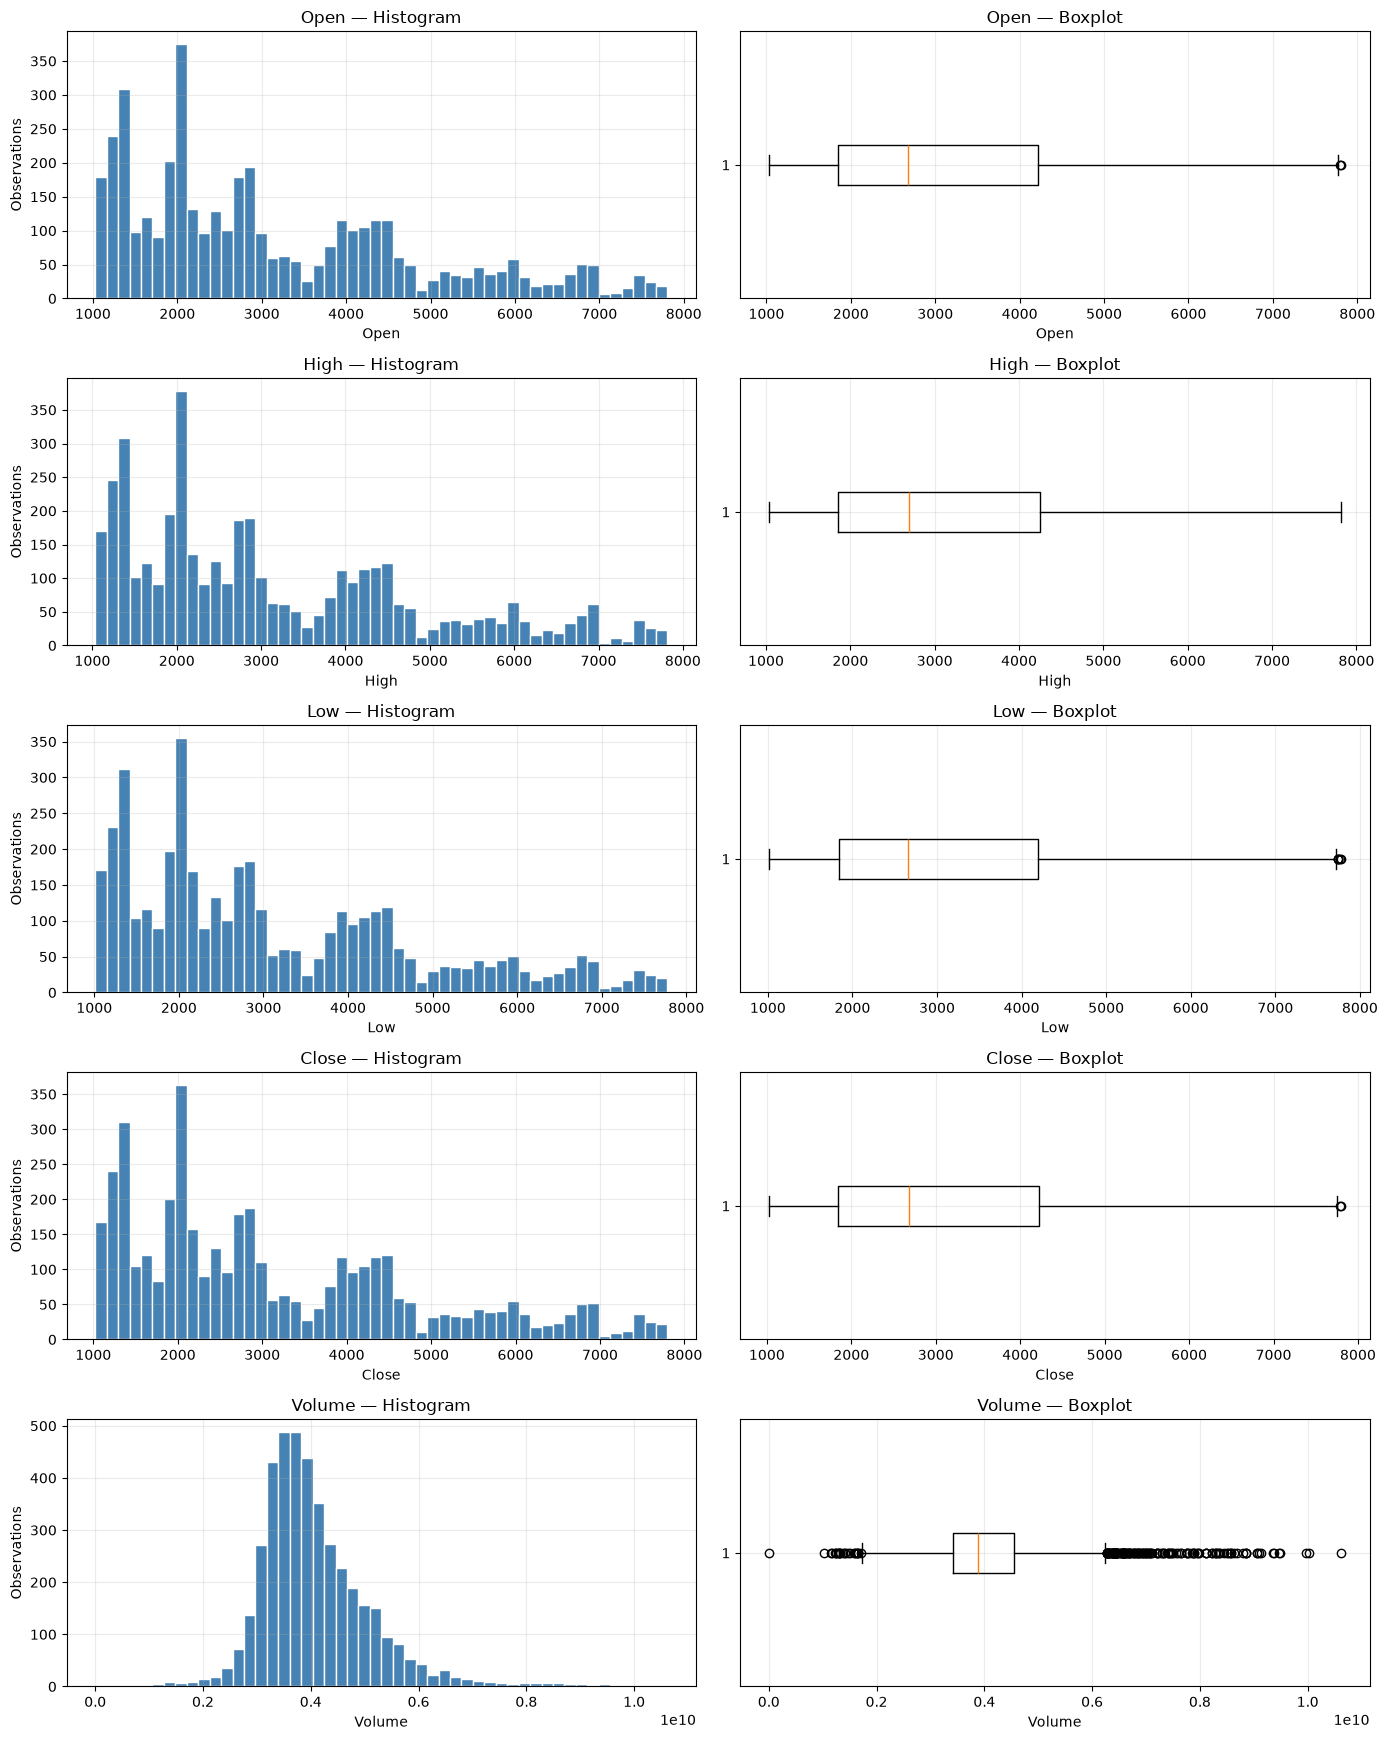

In [9]:

fig, axes = plt.subplots(len(RAW_NUMERIC), 2, figsize=(14, 3.5 * len(RAW_NUMERIC)), squeeze=False)
for row, column in enumerate(RAW_NUMERIC):
    values = raw_finite[column].dropna()
    if len(values):
        axes[row, 0].hist(values, bins=50, color='steelblue', edgecolor='white')
        axes[row, 1].boxplot(values, orientation='horizontal')
    axes[row, 0].set_title(column + ' — Histogram')
    axes[row, 0].set_xlabel(column)
    axes[row, 0].set_ylabel('Observations')
    axes[row, 1].set_title(column + ' — Boxplot')
    axes[row, 1].set_xlabel(column)
plt.tight_layout()
plt.show()

### 1.9 Diễn biến theo thời gian

Vẽ từng biến gốc riêng, giữ đơn vị riêng. Bảng theo năm hỗ trợ quan sát thay đổi quy mô. Một bước nhảy trên biểu đồ chỉ là candidate shock/structural break; cần xác minh trước khi gán nguyên nhân.


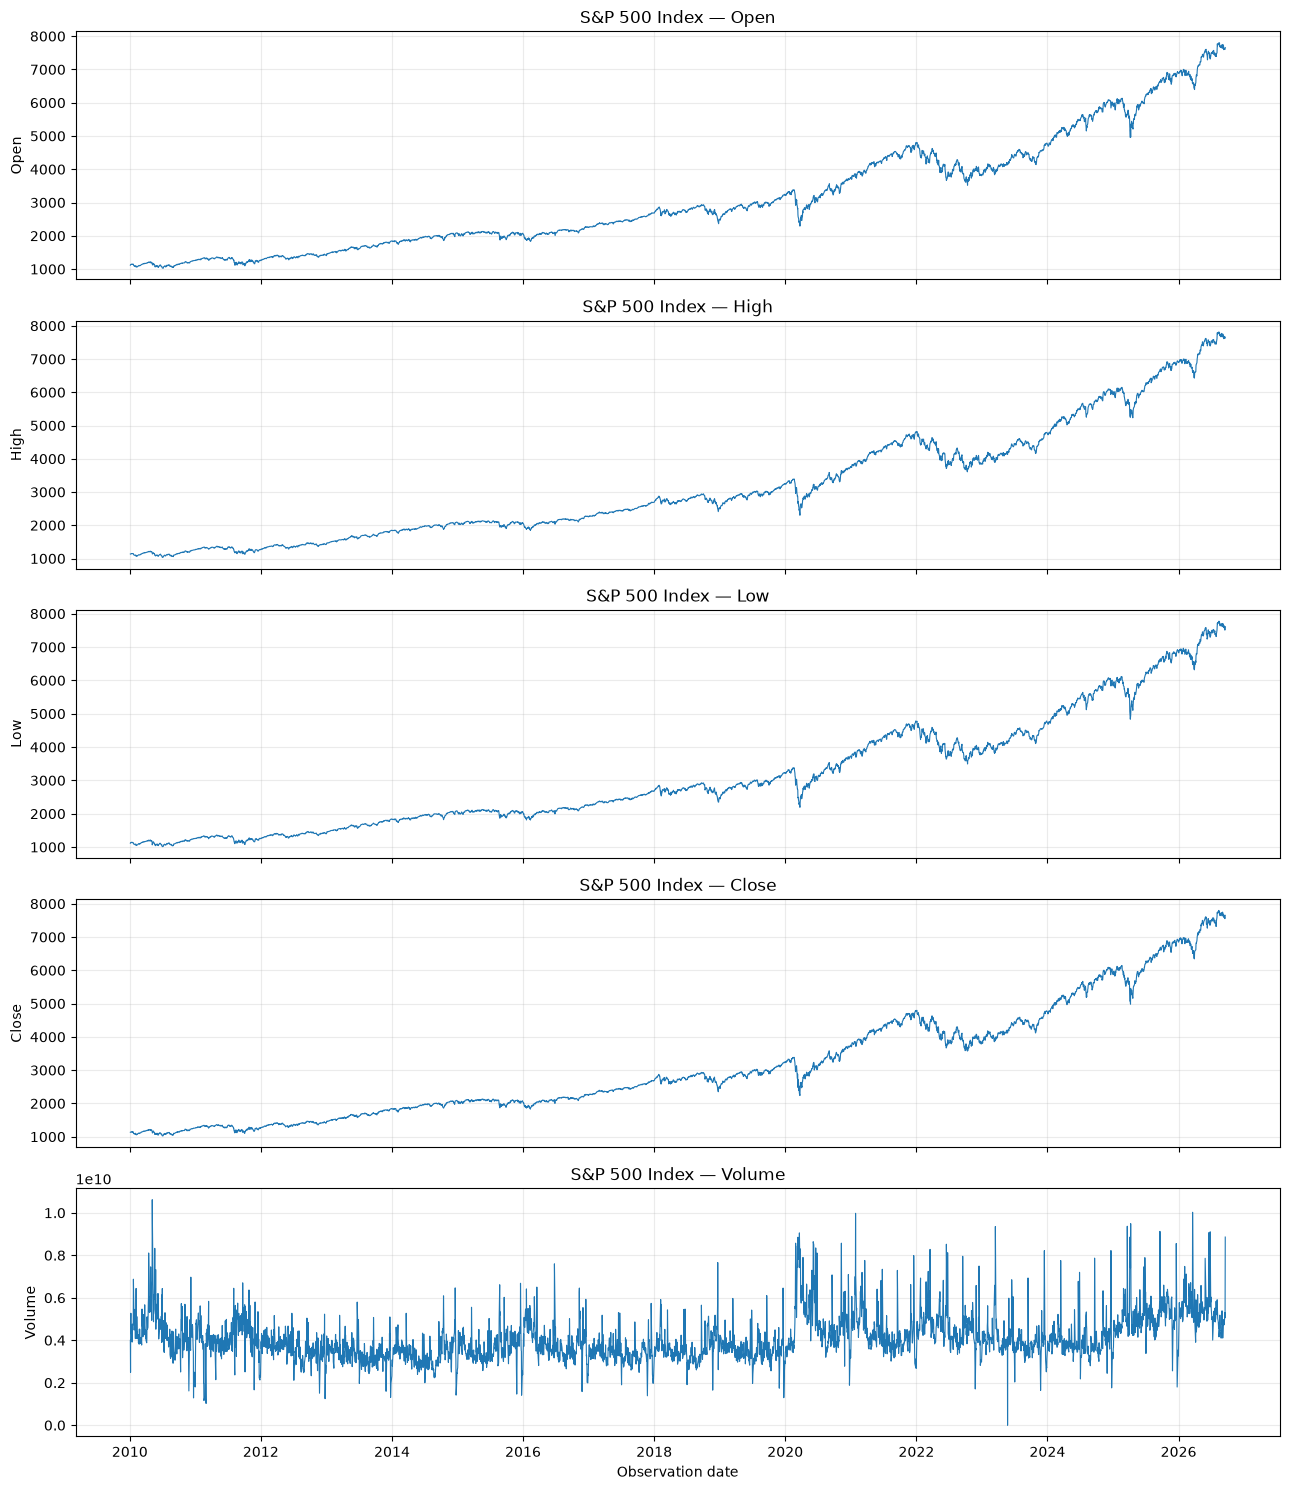


Thống kê các biến gốc theo năm


Open                                                                  \
     count         mean       median         std          min          max   
Date                                                                         
2010   252  1139.369761  1136.915039   55.669435  1027.650024  1259.439941   
2011   252  1267.618211  1282.275024   62.495858  1097.420044  1365.209961   
2012   250  1378.680638  1381.105042   47.134197  1258.859985  1465.420044   
2013   252  1642.298649  1649.135010   99.472828  1426.189941  1842.969971   
2014   252  1930.754485  1935.664978   79.505480  1743.819946  2088.489990   
2015   252  2061.268016  2078.630005   54.547528  1872.750000  2130.360107   
2016   252  2094.091550  2102.950073  101.083242  1833.400024  2270.540039   
2017   251  2448.275888  2435.750000  109.693698  2251.570068  2692.709961   
2018   251  2747.910717  2741.669922   99.127715  2363.120117  2936.760010   
2019   252  2911.627625  2917.295044  152.251818  2474.330078  3247.229980   
2020   253  3217.750272  3280.610107  318.362931  2290.709961  3750.010010   
2021   252  4271.170712  4298.564941  287.342362  3698.020020  4795.490234   
2022   251  4100.626447  4040.169922  293.622855  3520.370117  4804.509766   
2023   250  4280.813798  4284.995117  230.441677  3823.370117  4786.439941   
2024   252  5427.891094  5442.000000  369.643063  4690.569824  6089.029785   
2025   250  6215.344838  6238.679932  465.248132  4953.790039  6936.020020   
2026   179  7219.739394  7362.970215  375.525439  6395.879883  7806.600098   

      High                                        ...        Close  \
     count         mean       median         std  ...       median   
Date                                              ...                
2010   252  1146.573372  1144.619995   54.159387  ...  1136.984985   
2011   252  1277.223450  1287.520020   58.218464  ...  1281.895020   
2012   250  1385.845401  1390.619995   46.336040  ...  1383.669983   
2013   252  1649.615712  1656.144958   99.103795  ...  1650.404968   
2014   252  1938.835599  1944.294983   78.865382  ...  1937.350037   
2015   252  2071.862899  2086.964966   50.389886  ...  2079.395020   
2016   252  2103.306866  2111.405029   98.240098  ...  2104.104980   
2017   251  2454.344818  2442.229980  109.422392  ...  2436.100098   
2018   251  2762.645180  2754.600098   93.161420  ...  2743.149902   
2019   252  2923.622342  2930.895020  149.370509  ...  2919.024902   
2020   253  3242.183946  3288.129883  308.633058  ...  3276.020020   
2021   252  4291.877589  4325.770020  286.093489  ...  4304.000000   
2022   251  4134.732700  4076.810059  290.978607  ...  4027.260010   
2023   250  4303.630250  4318.495117  226.839243  ...  4291.160156   
2024   252  5451.176828  5478.929932  369.868330  ...  5435.435059   
2025   250  6248.653062  6252.385010  452.488403  ...  6228.699951   
2026   179  7254.120548  7396.560059  371.191002  ...  7354.020020   

                                           Volume                              \
             std          min          max  count          mean        median   
Date                                                                            
2010   56.201470  1022.580017  1259.780029    252  4.569371e+09  4.443190e+09   
2011   62.551356  1099.229980  1363.609985    252  4.109056e+09  4.133735e+09   
2012   46.626674  1277.060059  1465.770020    250  3.631677e+09  3.641915e+09   
2013   99.235112  1457.150024  1848.359985    252  3.358967e+09  3.331930e+09   
2014   79.815346  1741.890015  2090.570068    252  3.354783e+09  3.305540e+09   
2015   54.885790  1867.609985  2130.820068    252  3.655629e+09  3.576485e+09   
2016  101.427614  1829.079956  2271.719971    252  3.904086e+09  3.766130e+09   
2017  109.417247  2257.830078  2690.159912    251  3.420175e+09  3.394450e+09   
2018  100.409310  2351.100098  2930.750000    251  3.634743e+09  3.501380e+09   
2019  150.668307  2447.889893  3240.020020    252  3.558550e+09  3.51472

In [10]:

fig, axes = plt.subplots(len(RAW_NUMERIC), 1, figsize=(13, 3 * len(RAW_NUMERIC)), squeeze=False, sharex=True)
for row, column in enumerate(RAW_NUMERIC):
    axes[row, 0].plot(df['Date'], raw_finite[column], linewidth=.8)
    axes[row, 0].set_title(TITLE + ' — ' + column)
    axes[row, 0].set_ylabel(column)
axes[-1, 0].set_xlabel('Observation date')
plt.tight_layout()
plt.show()

annual_raw = raw_finite.groupby(df['Date'].dt.year).agg(['count','mean','median','std','min','max'])
print('\nThống kê các biến gốc theo năm')
display(annual_raw)

**Điểm cần chú ý riêng:** đây là mức chỉ số, không phải giá một cổ phiếu. Không so sánh quy mô Volume trực tiếp với futures hoặc Dollar Index.


## Part 2 — Feature-oriented EDA

Phân tích từng feature của **S&P 500** theo thứ tự: câu hỏi → đại lượng cần đo → cách tính → bảng/biểu đồ.

Cấu hình EDA: lag **1/2/3/5 phiên**, volatility **5/20/60 phiên**.

Các feature được tạo trên bản sao `sp500`, còn `df` giữ các biến gốc. Return và volatility lưu ở dạng tỷ lệ (0.01 = 1%), hiển thị theo %. Lag và cửa sổ tính theo phiên quan sát của chính nguồn.


### 2.0 Chuẩn bị dữ liệu và cấu hình

Giữ `df` của Part 1 nguyên vẹn, tạo bản sao `sp500`. Kiểm tra điều kiện tính feature bằng thông báo. Nếu Date/Close chưa hợp lệ, các cell tính toán sẽ in lý do bỏ qua thay vì tạo kết quả không đáng tin. OHLC cần kiểm tra riêng ở mục Intraday Range.


In [11]:

sp500 = df.copy()


LAGS = [1, 2, 3, 5]
VOL_WINDOWS = [5, 20, 60]


feature_ready = True
if sp500.empty:
    print('Cảnh báo: Dữ liệu rỗng; chưa tính feature.')
    feature_ready = False
if sp500['Date'].isna().any() or sp500['Date'].duplicated().any():
    print('Cảnh báo: Date thiếu hoặc trùng; cần kiểm tra lại Part 1.')
    feature_ready = False
if not sp500['Date'].is_monotonic_increasing:
    print('Cảnh báo: Date chưa tăng dần; cần kiểm tra thứ tự ở Part 1.')
    feature_ready = False
invalid_close = sp500['Close'].isna() | sp500['Close'].isin([float('inf'), -float('inf')]) | (sp500['Close'] <= 0)
if invalid_close.any():
    print(f'Cảnh báo: Có {int(invalid_close.sum())} Close thiếu, không hữu hạn hoặc không dương.')
    feature_ready = False
if feature_ready:
    print(f'Dữ liệu đủ điều kiện tính feature trên {len(sp500):,} phiên quan sát.')
    print('Các dòng warm-up sẽ để NaN, không fill bằng 0.')
else:
    print('Các cell feature bên dưới sẽ bỏ qua phép tính cho tới khi đầu vào được xử lý.')


feature_columns = []

Dữ liệu đủ điều kiện tính feature trên 4,203 phiên quan sát.
Các dòng warm-up sẽ để NaN, không fill bằng 0.


### 2.1 Daily Return

**Câu hỏi:** Giá S&P 500 hôm nay thay đổi bao nhiêu so với phiên quan sát trước?

**Ý nghĩa:** Đo biến động tương đối để giảm ảnh hưởng của mặt bằng giá dài hạn.

**Cách tính và đơn vị:** `Daily_Return(t) = Close(t) / Close(t−1) − 1`. Dòng đầu thiếu vì chưa có phiên trước. Không forward-fill.

**Thống kê và biểu đồ:** Bảng thống kê theo %, line chart, histogram/boxplot và 10 phiên có |return| lớn nhất. Các phiên cực trị chỉ được đánh dấu để rà soát, không bị xóa.



Thống kê Daily Return — đơn vị % mỗi phiên


,Return (%)
count,4202.000000
mean,0.051331
std,1.081870
min,-11.984055
1%,-3.101549
25%,-0.381186
50%,0.069200
75%,0.570538
99%,2.647737
max,9.515388


Số dòng thiếu do chưa có phiên trước: 1

10 phiên có độ lớn Daily Return cao nhất


,Date,Close,Return (%)
402,2011-08-08,1119.459961,-6.663446
2561,2020-03-09,2746.560059,-7.596970
2564,2020-03-12,2480.639893,-9.511268
2565,2020-03-13,2711.020020,9.287125
2566,2020-03-16,2386.129883,-11.984055
2567,2020-03-17,2529.189941,5.995485
2572,2020-03-24,2447.330078,9.382774
2574,2020-03-26,2630.070068,6.241416
2581,2020-04-06,2663.679932,7.033132
3840,2025-04-09,5456.899902,9.515388


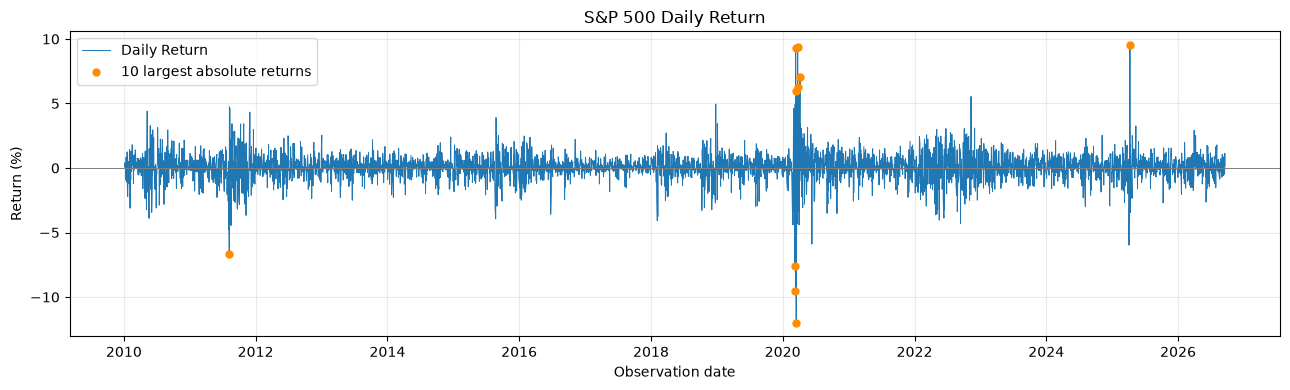

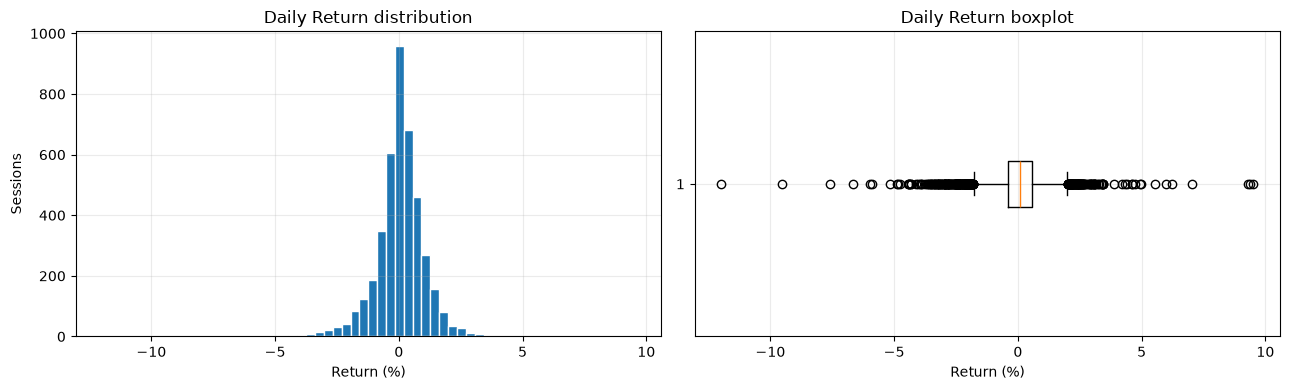

In [12]:
if feature_ready:
    
    sp500['Daily_Return'] = sp500['Close'].pct_change(fill_method=None)
    feature_columns.append('Daily_Return')
    return_percent = sp500['Daily_Return'] * 100

    print('\nThống kê Daily Return — đơn vị % mỗi phiên')
    display(return_percent.describe(percentiles=[.01, .25, .5, .75, .99]).to_frame('Return (%)'))
    print('Số dòng thiếu do chưa có phiên trước:', int(sp500['Daily_Return'].isna().sum()))

    
    extreme_rows = sp500['Daily_Return'].abs().nlargest(10).index
    extreme_table = sp500.loc[extreme_rows, ['Date', 'Close']].copy()
    extreme_table['Return (%)'] = return_percent.loc[extreme_rows]
    print('\n10 phiên có độ lớn Daily Return cao nhất')
    display(extreme_table.sort_values('Date'))

    
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(sp500['Date'], return_percent, linewidth=.7, label='Daily Return')
    ax.scatter(sp500.loc[extreme_rows, 'Date'], return_percent.loc[extreme_rows],
               color='darkorange', s=25, label='10 largest absolute returns', zorder=3)
    ax.axhline(0, color='gray', linewidth=.7)
    ax.set(title='S&P 500 Daily Return', xlabel='Observation date', ylabel='Return (%)')
    ax.legend()
    plt.tight_layout()
    plt.show()

    
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(return_percent.dropna(), bins=60, edgecolor='white')
    axes[0].set(title='Daily Return distribution', xlabel='Return (%)', ylabel='Sessions')
    axes[1].boxplot(return_percent.dropna(), orientation='horizontal')
    axes[1].set(title='Daily Return boxplot', xlabel='Return (%)')
    plt.tight_layout()
    plt.show()
else:
    print('Chưa tính Daily Return: kiểm tra thông báo ở mục 2.0.')

### 2.2 Lagged Return

**Câu hỏi:** Biến động các phiên trước có đi cùng quán tính hoặc đảo chiều trong chính S&P 500 không?

**Ý nghĩa:** Đặt giả thuyết momentum/reversal từ lịch sử, chưa kiểm tra khả năng dự báo Gold t+1.

**Cách tính và đơn vị:** `Return_Lag_k(t) = Daily_Return(t−k)` bằng `shift(k)`, k = 1,2,3,5 phiên. Đây không phải số ngày lịch.

**Thống kê và biểu đồ:** Bảng mapping ngày hiện tại/ngày nguồn, số cặp hợp lệ, correlation nội chuỗi và scatter từng lag với return hiện tại.



Lag 1 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Return (%)
0,2010-01-04,NaT,NaN
1,2010-01-05,2010-01-04,NaN
2,2010-01-06,2010-01-05,0.311568
3,2010-01-07,2010-01-06,0.054552
4,2010-01-08,2010-01-07,0.400120
5,2010-01-11,2010-01-08,0.288173
6,2010-01-12,2010-01-11,0.174676
7,2010-01-13,2010-01-12,-0.938117



Lag 2 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Return (%)
0,2010-01-04,NaT,NaN
1,2010-01-05,NaT,NaN
2,2010-01-06,2010-01-04,NaN
3,2010-01-07,2010-01-05,0.311568
4,2010-01-08,2010-01-06,0.054552
5,2010-01-11,2010-01-07,0.400120
6,2010-01-12,2010-01-08,0.288173
7,2010-01-13,2010-01-11,0.174676



Lag 3 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Return (%)
0,2010-01-04,NaT,NaN
1,2010-01-05,NaT,NaN
2,2010-01-06,NaT,NaN
3,2010-01-07,2010-01-04,NaN
4,2010-01-08,2010-01-05,0.311568
5,2010-01-11,2010-01-06,0.054552
6,2010-01-12,2010-01-07,0.400120
7,2010-01-13,2010-01-08,0.288173



Lag 5 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Return (%)
0,2010-01-04,NaT,NaN
1,2010-01-05,NaT,NaN
2,2010-01-06,NaT,NaN
3,2010-01-07,NaT,NaN
4,2010-01-08,NaT,NaN
5,2010-01-11,2010-01-04,NaN
6,2010-01-12,2010-01-05,0.311568
7,2010-01-13,2010-01-06,0.054552


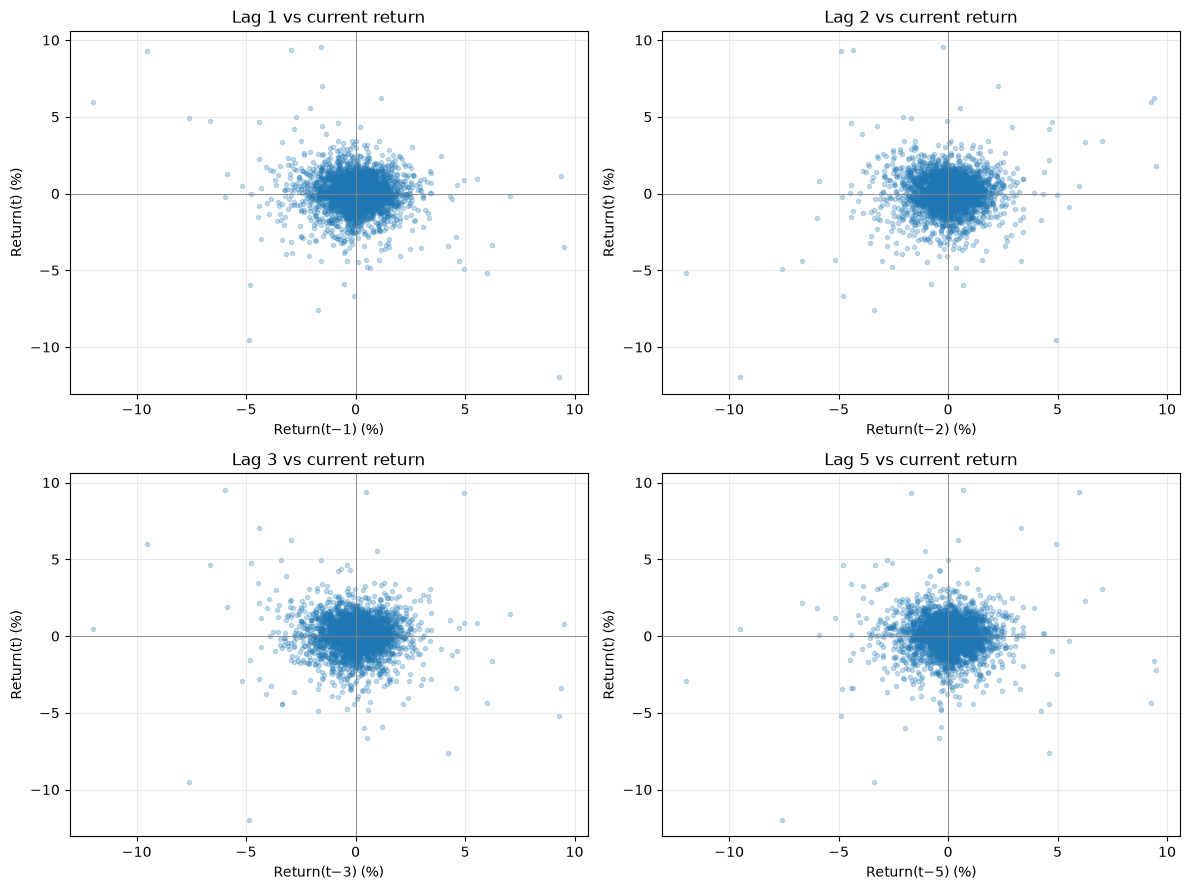


Tóm tắt lag — correlation mô tả toàn kỳ, không dùng để chọn lag


,Lag (sessions),Valid pairs,Missing lag values,Correlation with current return
0,1,4201,2,-0.113656
1,2,4200,3,0.067670
2,3,4199,4,-0.044757
3,5,4197,6,0.002361


In [13]:
if feature_ready:
    lag_summary = []
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    for lag, ax in zip(LAGS, axes.flat):
        
        column = f'Return_Lag_{lag}'
        sp500[column] = sp500['Daily_Return'].shift(lag)
        feature_columns.append(column)

        
        mapping = sp500[['Date']].copy()
        mapping['Source_date'] = sp500['Date'].shift(lag)
        mapping['Lagged Return (%)'] = sp500[column] * 100
        print(f'\nLag {lag} phiên — 8 dòng đầu của mapping ngày nguồn')
        display(mapping.head(8))

        
        pair = sp500[[column, 'Daily_Return']].dropna()
        lag_summary.append({'Lag (sessions)': lag, 'Valid pairs': len(pair),
                            'Missing lag values': int(sp500[column].isna().sum()),
                            'Correlation with current return': pair[column].corr(pair['Daily_Return'])})
        ax.scatter(pair[column] * 100, pair['Daily_Return'] * 100, s=9, alpha=.25)
        ax.axhline(0, color='gray', linewidth=.6)
        ax.axvline(0, color='gray', linewidth=.6)
        ax.set(title=f'Lag {lag} vs current return', xlabel=f'Return(t−{lag}) (%)', ylabel='Return(t) (%)')
    plt.tight_layout()
    plt.show()
    print('\nTóm tắt lag — correlation mô tả toàn kỳ, không dùng để chọn lag')
    display(pd.DataFrame(lag_summary))
else:
    print('Chưa tính Lagged Return: kiểm tra mục 2.0.')

### 2.3 Rolling Volatility

**Câu hỏi:** Thị trường gần đây đang yên bình hay biến động mạnh?

**Ý nghĩa:** Mô tả trạng thái rủi ro/biến động của S&P 500 qua các horizon khác nhau.

**Cách tính và đơn vị:** Độ lệch chuẩn mẫu (`ddof=1`) của Daily_Return trong 5/20/60 phiên gần nhất, gồm t. `min_periods=window`; không annualize.

**Thống kê và biểu đồ:** Biểu đồ ba đường volatility, thống kê và số dòng warm-up, boxplot để so độ phân tán.



Rolling Volatility — thống kê theo %, chưa annualize


,count,mean,std,min,25%,50%,75%,max
Volatility_5,4198.0,0.868803,0.679249,0.053027,0.460687,0.715688,1.076155,9.449468
Volatility_20,4183.0,0.925001,0.577710,0.207155,0.590696,0.780982,1.087671,6.118244
Volatility_60,4143.0,0.962960,0.508350,0.314438,0.686719,0.812216,1.072126,4.005500


Volatility_5: 5 dòng thiếu do warm-up.
Volatility_20: 20 dòng thiếu do warm-up.
Volatility_60: 60 dòng thiếu do warm-up.


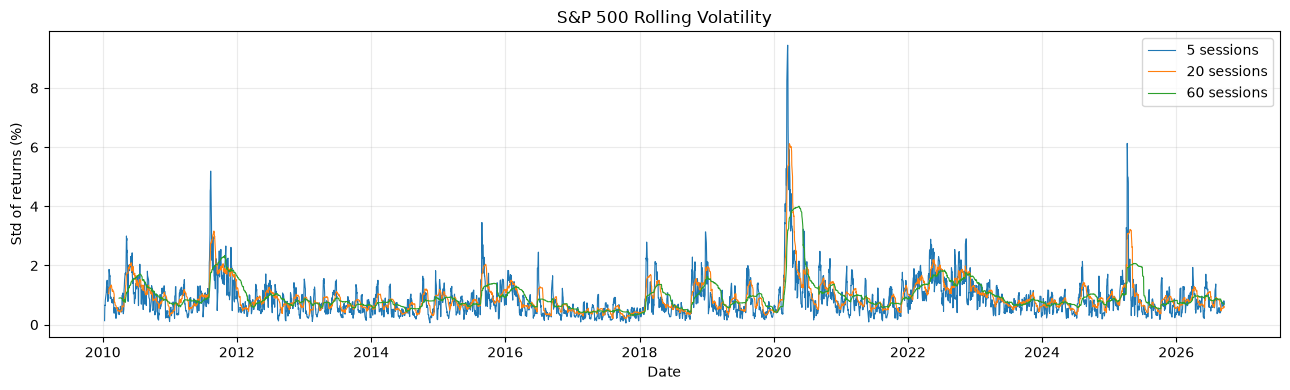

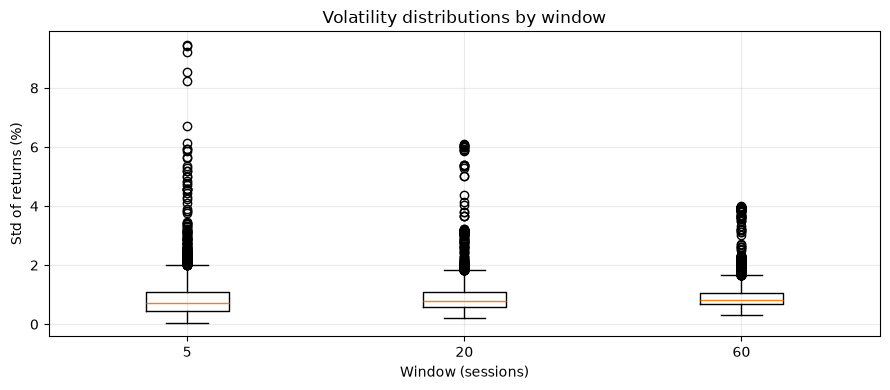

In [14]:
if feature_ready:
    volatility_names = []
    for window in VOL_WINDOWS:
        
        column = f'Volatility_{window}'
        sp500[column] = sp500['Daily_Return'].rolling(window=window, min_periods=window).std(ddof=1)
        volatility_names.append(column)
        feature_columns.append(column)

    print('\nRolling Volatility — thống kê theo %, chưa annualize')
    display((sp500[volatility_names] * 100).describe().T)
    for column in volatility_names:
        print(f'{column}: {int(sp500[column].isna().sum())} dòng thiếu do warm-up.')

    fig, ax = plt.subplots(figsize=(13, 4))
    for window, column in zip(VOL_WINDOWS, volatility_names):
        ax.plot(sp500['Date'], sp500[column] * 100, linewidth=.8, label=f'{window} sessions')
    ax.set(title='S&P 500 Rolling Volatility', xlabel='Date', ylabel='Std of returns (%)')
    ax.legend()
    plt.tight_layout()
    plt.show()

    
    box_values = [(sp500[column].dropna() * 100).tolist() for column in volatility_names]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.boxplot(box_values, tick_labels=[str(w) for w in VOL_WINDOWS])
    ax.set(title='Volatility distributions by window', xlabel='Window (sessions)', ylabel='Std of returns (%)')
    plt.tight_layout()
    plt.show()
else:
    print('Chưa tính Rolling Volatility: kiểm tra mục 2.0.')

### 2.4 Drawdown

**Câu hỏi:** Chỉ số đang thấp hơn bao nhiêu so với đỉnh đã quan sát?

**Ý nghĩa:** Mô tả mức suy giảm tích lũy, khác với biến động của một phiên.

**Cách tính và đơn vị:** Running_Peak=Close.cummax(); Drawdown=Close/Running_Peak−1. Đỉnh chỉ tính từ đầu snapshot; không dùng đỉnh tương lai.

**Thống kê và biểu đồ:** Close với running peak, drawdown theo thời gian, histogram và 10 ngày drawdown sâu nhất.



Thống kê Drawdown — đơn vị % so với đỉnh đã quan sát


,Drawdown (%)
count,4203.000000
mean,-4.164160
std,5.285823
min,-33.924960
25%,-6.060401
50%,-1.937403
75%,-0.376438
max,0.000000



10 ngày Drawdown sâu nhất — có thể thuộc cùng một đợt giảm


,Date,Close,Running_Peak,Drawdown (%)
2571,2020-03-23,2237.399902,3386.149902,-33.924960
2570,2020-03-20,2304.919922,3386.149902,-31.930954
2566,2020-03-16,2386.129883,3386.149902,-29.532657
2568,2020-03-18,2398.100098,3386.149902,-29.179151
2569,2020-03-19,2409.389893,3386.149902,-28.845740
2572,2020-03-24,2447.330078,3386.149902,-27.725288
2578,2020-04-01,2470.500000,3386.149902,-27.041033
2573,2020-03-25,2475.560059,3386.149902,-26.891599
2564,2020-03-12,2480.639893,3386.149902,-26.741581
2580,2020-04-03,2488.649902,3386.149902,-26.505029


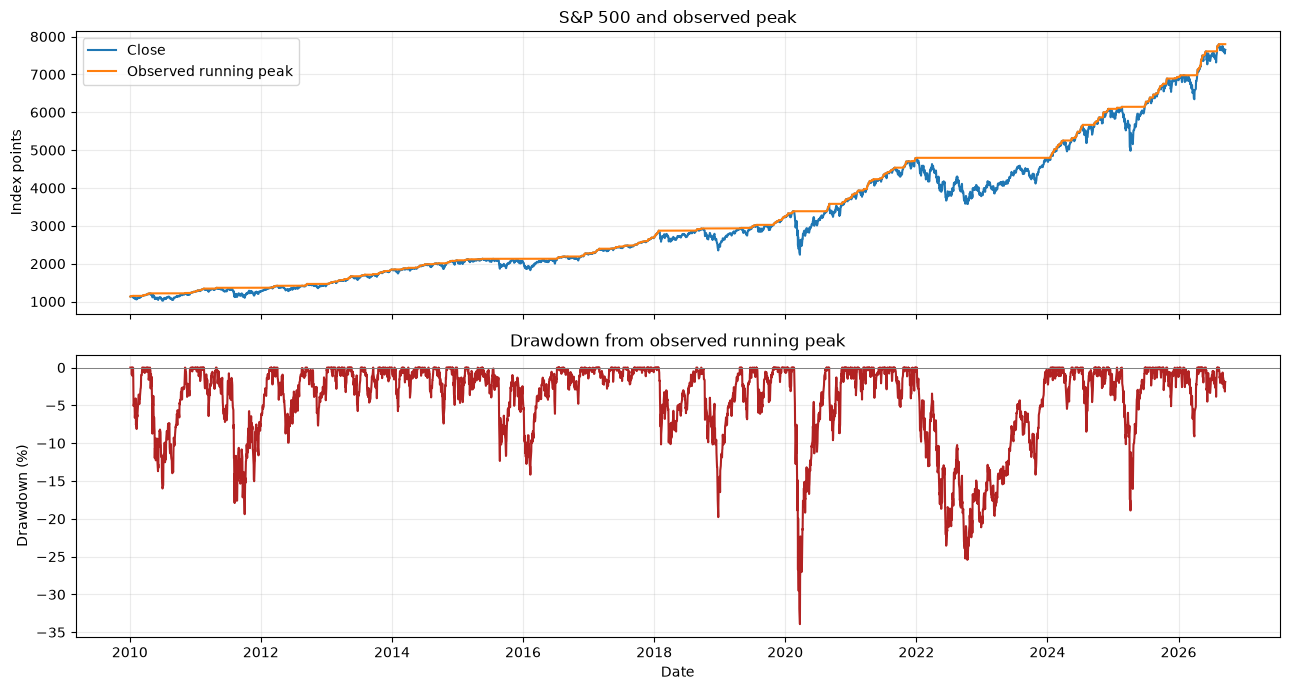

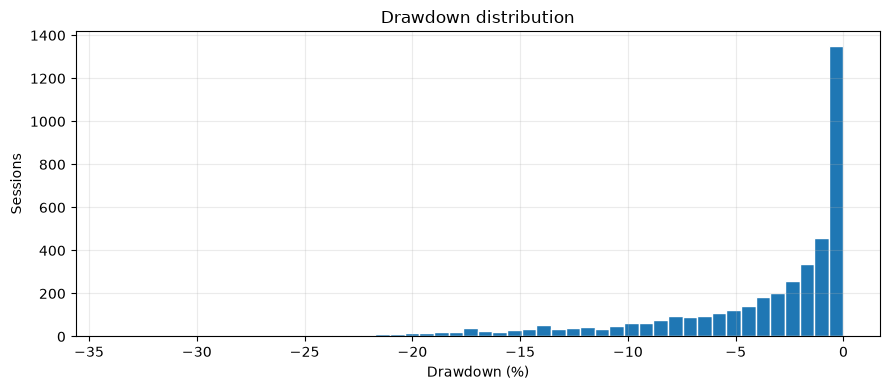

In [15]:
if feature_ready:
    
    sp500['Running_Peak'] = sp500['Close'].cummax()
    sp500['Drawdown'] = sp500['Close'] / sp500['Running_Peak'] - 1
    feature_columns.append('Drawdown')
    print('\nThống kê Drawdown — đơn vị % so với đỉnh đã quan sát')
    display((sp500['Drawdown'] * 100).describe().to_frame('Drawdown (%)'))
    deepest = sp500.nsmallest(10, 'Drawdown')[['Date', 'Close', 'Running_Peak']].copy()
    deepest['Drawdown (%)'] = sp500.loc[deepest.index, 'Drawdown'] * 100
    print('\n10 ngày Drawdown sâu nhất — có thể thuộc cùng một đợt giảm')
    display(deepest)

    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    axes[0].plot(sp500['Date'], sp500['Close'], label='Close')
    axes[0].plot(sp500['Date'], sp500['Running_Peak'], label='Observed running peak')
    axes[0].set(title='S&P 500 and observed peak', ylabel='Index points')
    axes[0].legend()
    axes[1].plot(sp500['Date'], sp500['Drawdown'] * 100, color='firebrick')
    axes[1].axhline(0, color='gray', linewidth=.7)
    axes[1].set(title='Drawdown from observed running peak', xlabel='Date', ylabel='Drawdown (%)')
    plt.tight_layout()
    plt.show()
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(sp500['Drawdown'] * 100, bins=50, edgecolor='white')
    ax.set(title='Drawdown distribution', xlabel='Drawdown (%)', ylabel='Sessions')
    plt.tight_layout()
    plt.show()
else:
    print('Chưa tính Drawdown: kiểm tra mục 2.0.')

### 2.5 Drawdown và Rolling Volatility

**Câu hỏi:** Mức giảm so với đỉnh đi cùng mức biến động gần đây như thế nào?

Biểu đồ scatter đối chiếu Drawdown với Volatility 5/20/60 phiên để mô tả các vùng dữ liệu. Hai trục hiển thị theo %.


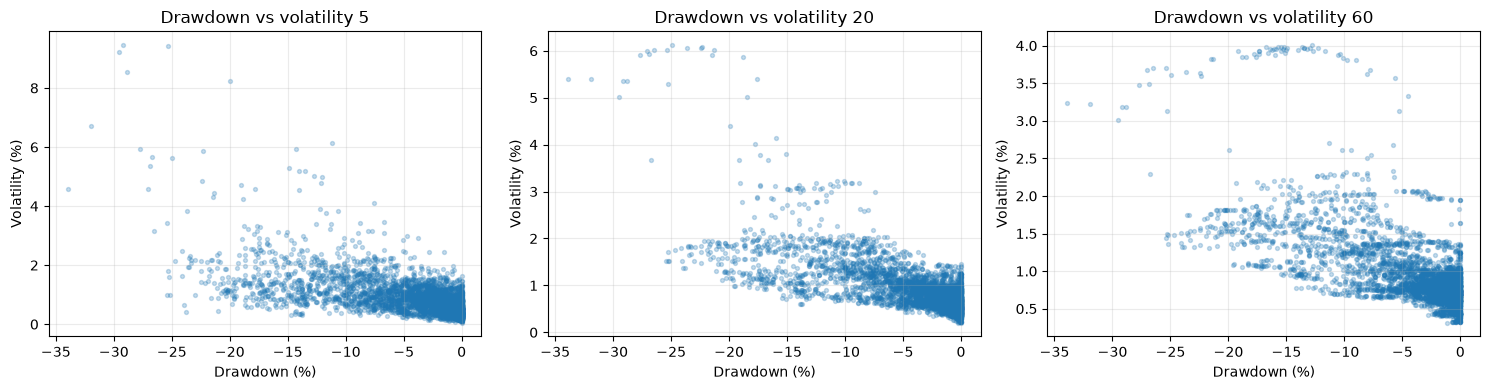

In [16]:
if feature_ready:
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for window, ax in zip(VOL_WINDOWS, axes):
        ax.scatter(sp500['Drawdown'] * 100, sp500[f'Volatility_{window}'] * 100, s=8, alpha=.25)
        ax.set(title=f'Drawdown vs volatility {window}', xlabel='Drawdown (%)', ylabel='Volatility (%)')
    plt.tight_layout()
    plt.show()